<a href="https://colab.research.google.com/github/zinofiad824-cloud/-ppi-ml-learning/blob/main/PMI_F3L_descriptors_csv.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

{'PMI': 'TSFAEYWNLLSP', 'p53-derived': 'ETFSDLWKLLPE', 'PMI-F3A': 'TSAAEYWNLLSP', 'PMI-W7A': 'TSFAEYANLLSP', 'PMI-L9A': 'TSFAEYWNALSP', 'PMI-L10A': 'TSFAEYWNLASP'}
Original: TSFAEYWNLLSP
PMI-F3L:   TSLAEYWNLLSP


,Name,Sequence,Length,Molecular_weight,Aromaticity,GRAVY
0,PMI,TSFAEYWNLLSP,12,1427.556,0.250,-0.075
1,p53-derived,ETFSDLWKLLPE,12,1477.656,0.167,-0.350
2,PMI-F3A,TSAAEYWNLLSP,12,1351.460,0.167,-0.158
3,PMI-W7A,TSFAEYANLLSP,12,1312.424,0.167,0.150
4,PMI-L9A,TSFAEYWNALSP,12,1385.476,0.250,-0.242
5,PMI-L10A,TSFAEYWNLASP,12,1385.476,0.250,-0.242


,Name,Sequence,Length,Molecular_weight,Aromaticity,GRAVY
0,PMI,TSFAEYWNLLSP,12,1427.556,0.25,-0.075


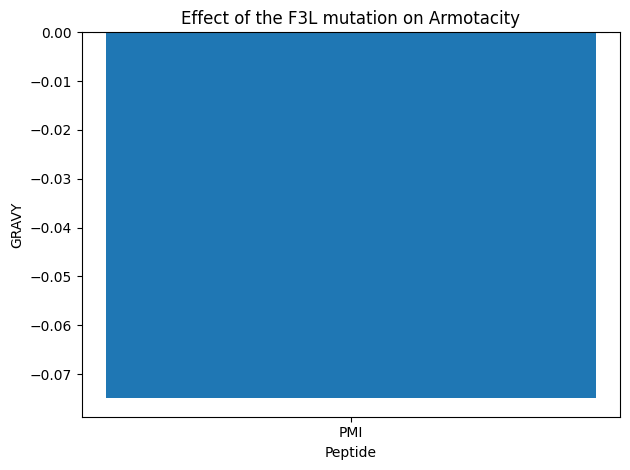

In [4]:

%pip install -q biopython pandas matplotlib
import pandas as pd
import matplotlib.pyplot as plt

from Bio.SeqUtils.ProtParam import ProteinAnalysis
peptides = {
    "PMI": "TSFAEYWNLLSP",
    "p53-derived": "ETFSDLWKLLPE",
    "PMI-F3A": "TSAAEYWNLLSP",
    "PMI-W7A": "TSFAEYANLLSP",
    "PMI-L9A": "TSFAEYWNALSP",
    "PMI-L10A": "TSFAEYWN L A SP".replace(" ", "")
}

print(peptides)
original = peptides["PMI"]

mutant = original[:2] + "L" + original[3:]

print("Original:", original)
print("PMI-F3L:  ", mutant)
def analyze_peptide(name, sequence):

    analysis = ProteinAnalysis(sequence)

    return {
        "Name": name,
        "Sequence": sequence,
        "Length": len(sequence),
        "Molecular_weight": analysis.molecular_weight(),
        "Aromaticity": analysis.aromaticity(),
        "GRAVY": analysis.gravy()
    }


results = []

for name, sequence in peptides.items():
    result = analyze_peptide(name, sequence)
    results.append(result)

df = pd.DataFrame(results)

display(df.round(3))
comparison = df[
    df["Name"].isin(["PMI", "PMI-F3L"])
]

display(comparison.round(3))
plt.bar(
    comparison["Name"],
    comparison["GRAVY"]
)

plt.axhline(0, color="gray", linestyle="--")

plt.xlabel("Peptide")

plt.ylabel("GRAVY")

plt.title("Effect of the F3L mutation on Armotacity")

plt.tight_layout()

plt.savefig("PMI_F3L_Aroma.png", dpi=300)

plt.show()





In [7]:
df.to_csv("PMI_F3L_descriptors.csv", index=False)

print("Dataset saved successfully.")
from google.colab import files

files.download("PMI_F3L_descriptors.csv")

files.download("PMI_F3L_GRAVY.png")

Dataset saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>